# Compare the first two Python and MATLAB plots
Run the Python and MATLAB producers first. This compares plotted coordinates,
selected particles, reference phase, cavity background, harmonics and axis limits.
It does not compare screenshots pixel by pixel. Both engines use their own test 7 solution.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat

current = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current, *current.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "large_signal_1d.py").is_file()
)
test_directory = project_directory / "test" / "8.ApplegateDiagramTest"
source_directory = project_directory / "test" / "7.nonlinear_iteration_test"
sys.path.insert(0, str(project_directory / "src"))
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True,
    "grid.color": "gray", "grid.linestyle": "--", "grid.alpha": 0.45,
})

In [2]:
python = loadmat(test_directory / "python_results.mat", squeeze_me=False)
matlab = loadmat(test_directory / "matlab_results.mat", squeeze_me=False)
inputs = loadmat(test_directory / "inputs.mat", squeeze_me=True)
source_inputs = loadmat(source_directory / "inputs.mat", squeeze_me=True)
for data in (python, matlab):
    assert str(data["run_id"].item()) == str(inputs["run_id"]), "Stale test 8 output."
    assert str(data["source_run_id"].item()) == str(source_inputs["run_id"]), "Rerun test 8 after changing test 7."

indices = {"ntemp", "ncenter", "selected"}
exact = indices | {"stride"}
vectors = {"selected", "zi", "ez_background", "harmonic_widths", "xlim",
           "phase_ylim", "field_ylim", "harmonic_xlim"}
keys = {name for name in python if not name.startswith("__")} - {"run_id", "source_run_id"}
assert keys == {name for name in matlab if not name.startswith("__")} - {"run_id", "source_run_id"}

print("quantity                    max absolute difference")
for name in sorted(keys):
    a = np.asarray(python[name])
    b = np.asarray(matlab[name])
    if name in vectors:
        a, b = a.ravel(), b.ravel()
    if name in indices:
        b = b - 1  # MATLAB indices are one-based.
    assert a.shape == b.shape, (name, a.shape, b.shape)
    np.testing.assert_array_equal(np.isnan(a), np.isnan(b), err_msg=name)
    np.testing.assert_array_equal(np.isinf(a), np.isinf(b), err_msg=name)
    if name in exact:
        np.testing.assert_array_equal(a, b, err_msg=name)
    else:
        np.testing.assert_allclose(a, b, rtol=1e-8, atol=1e-10, equal_nan=True, err_msg=name)
    finite = np.isfinite(a) & np.isfinite(b)
    difference = np.max(np.abs(a[finite] - b[finite])) if np.any(finite) else 0.0
    print(f"{name:28s} {difference:.3e}")
print("PASS: selected particles and plotted data agree.")

quantity                    max absolute difference
Izmax                        0.000e+00
cavity_x                     0.000e+00
cavity_y                     0.000e+00
ez_background                6.896e-17
field_ylim                   0.000e+00
harmonic_amplitudes          1.199e-14
harmonic_widths              0.000e+00
harmonic_xlim                0.000e+00
ncenter                      0.000e+00
ntemp                        0.000e+00
phase                        8.527e-14
phase_ylim                   0.000e+00
selected                     0.000e+00
stride                       0.000e+00
x_phase                      4.547e-13
xlim                         0.000e+00
zi                           4.547e-13
PASS: selected particles and plotted data agree.


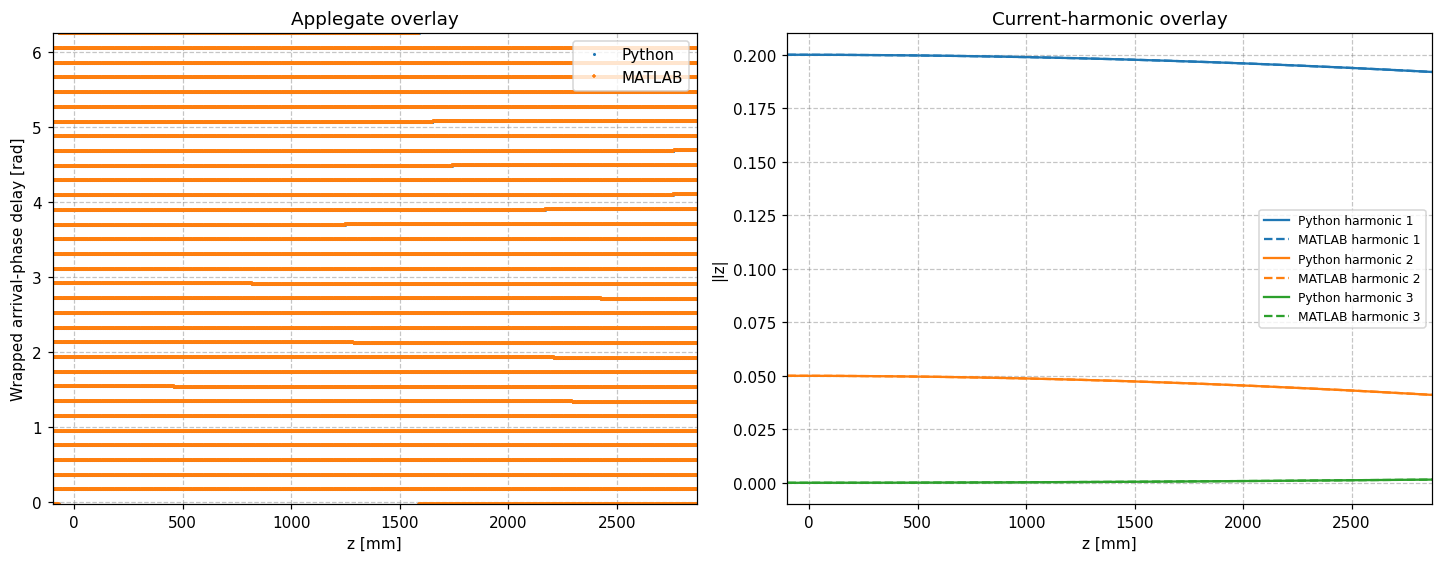

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for data, color, marker, label in [
    (python, "tab:blue", ".", "Python"), (matlab, "tab:orange", "+", "MATLAB"),
]:
    axes[0].plot(data["x_phase"].ravel(), data["phase"].ravel(),
                 linestyle="none", marker=marker, markersize=2, color=color, label=label)
axes[0].set(xlabel="z [mm]", ylabel="Wrapped arrival-phase delay [rad]", title="Applegate overlay")
axes[0].set_xlim(*python["xlim"].ravel())
axes[0].set_ylim(*python["phase_ylim"].ravel())
axes[0].legend()

zi = python["zi"].ravel()
for k in range(python["harmonic_amplitudes"].shape[1]):
    line, = axes[1].plot(zi, python["harmonic_amplitudes"][:, k], label=f"Python harmonic {k+1}")
    axes[1].plot(matlab["zi"].ravel(), matlab["harmonic_amplitudes"][:, k],
                 "--", color=line.get_color(), label=f"MATLAB harmonic {k+1}")
axes[1].set(xlabel="z [mm]", ylabel="|Iz|", title="Current-harmonic overlay")
axes[1].set_xlim(*python["harmonic_xlim"].ravel())
axes[1].legend(fontsize=8)
fig.savefig(test_directory / "comparison.png", dpi=150)
plt.show()